# 01 · The alarm log

**What the plant writes.** Every PLC on the line reports its faults to the SCADA system. The export has one row per alert:

| Column | Meaning |
|---|---|
| `alertId` | unique, increases with every new alert |
| `alertBegin`, `alertEnd` | when the alert started and cleared |
| `alertTotalDuration` | the difference, as HH:MM:SS |
| `alertIsBandStop` | did the line stop |
| `alertIsTpm` | did a TPM round take place during the alert |
| `alertCategory` | technical, organizational or other |
| `alertText` | the fault message, in German |
| `alertPlc` | the PLC that raised it |

The original data, 9.35M alerts from 75 PLCs over one year, is under NDA. This repository generates its own alarm log with the same columns.

**The generated plant**
- 75 PLCs on three lines, in process order: presses, welding, robot cells, conveyors, buffers, assembly, measuring, test stands
- Three shifts on weekdays with breaks, low traffic at weekends
- **Background alerts:** ordinary faults, each from a fixed set of messages per station
- **Error cascades:** a root fault followed by 3 to 12 more alerts, 5 to 250 ms apart, on the same PLC or a neighbouring one
- **Repeating devices:** one message fired 4 to 30 times within a few seconds. Not a cascade, but it looks like one in time

The generator writes which alert belongs to which cascade into `ground_truth.csv`. The pipeline never reads that file; only the scoring in notebooks 02 to 06 does.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

from central_logging import config, plotting
from central_logging.plotting import SERIES, MUTED, TEXT, TEXT_2

plotting.use_style()
pd.set_option("display.max_colwidth", 90)
RESULTS = ROOT / "results"
FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
from central_logging.generate import DEFAULTS, generate, alert_day

alerts, truth, plant = generate()
print(f"{len(alerts):,} alerts, {alerts.alertPlc.nunique()} PLCs, {alert_day(alerts).nunique()} days, "
      f"{alerts.alertText.nunique():,} distinct messages")
alerts.head()

172,322 alerts, 75 PLCs, 14 days, 1,866 distinct messages


,alertId,alertBegin,alertEnd,alertTotalDuration,alertIsBandStop,alertIsTpm,alertCategory,alertText,alertPlc
0,10000001,2024-04-08 00:02:10.2313681 +02:00,2024-04-08 00:02:18.5775819 +02:00,00:00:08,0,0,technical,HY9 Hydraulik 7 Druck zu niedrig,B1PRS03
1,10000002,2024-04-08 00:02:12.4419611 +02:00,2024-04-08 00:02:17.4839285 +02:00,00:00:05,0,0,technical,WT5 Werkstuecktraeger 6 nicht gelesen,B1PUF01
2,10000003,2024-04-08 00:02:23.9193340 +02:00,2024-04-08 00:02:28.5461794 +02:00,00:00:04,0,0,technical,MO3 Motor 19 Uebertemperatur,A1MES02
3,10000004,2024-04-08 00:04:22.6360791 +02:00,2024-04-08 00:04:22.9540678 +02:00,00:00:00,0,0,technical,MO3 Motor 18 Uebertemperatur,A1PRS03
4,10000005,2024-04-08 00:05:15.3173188 +02:00,2024-04-08 00:05:27.4789642 +02:00,00:00:12,0,0,technical,MW2 Messwert 2 unplausibel,A2KLB03


In [3]:
kind = truth.cascade_role.map({"root": "error cascade", "link": "error cascade",
                               "repeat": "repeating device", "none": "background"})
print(f"{truth.loc[truth.cascade_id >= 0, 'cascade_id'].nunique():,} cascades, "
      f"{truth.loc[truth.burst_id >= 0, 'burst_id'].nunique():,} repeating-device bursts")
pd.DataFrame({"alerts": kind.value_counts(), "share": kind.value_counts(normalize=True).round(3)})

4,986 cascades, 1,247 repeating-device bursts


,alerts,share
cascade_role,,
background,114265,0.663
error cascade,37142,0.216
repeating device,20915,0.121


## When alerts happen

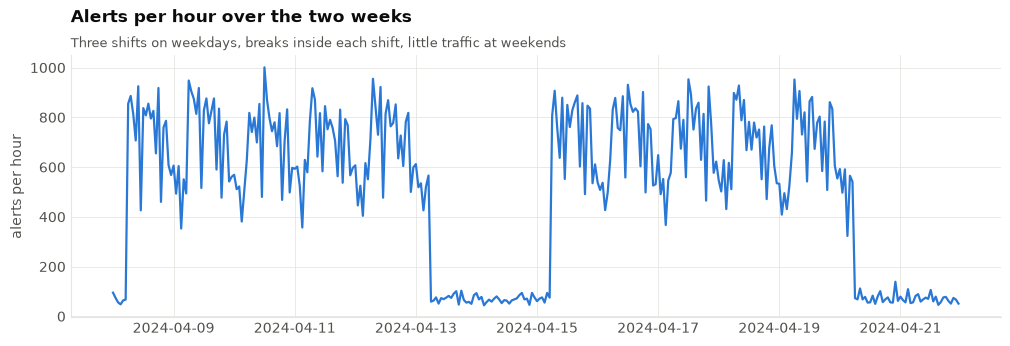

In [4]:
ts = pd.to_datetime(alerts.alertBegin.str[:19])
hourly = ts.dt.floor("h").value_counts().sort_index()
hourly = hourly.reindex(pd.date_range(hourly.index.min().normalize(), periods=14 * 24, freq="h"), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 3.4))
ax.plot(hourly.index, hourly.values, color=SERIES[0], lw=1.6)
ax.set_title("Alerts per hour over the two weeks")
plotting.subtitle(ax, "Three shifts on weekdays, breaks inside each shift, little traffic at weekends")
ax.set_ylabel("alerts per hour")
fig.savefig(FIG / "data_alerts_per_hour.png")
plt.show()

## Which PLCs raise them

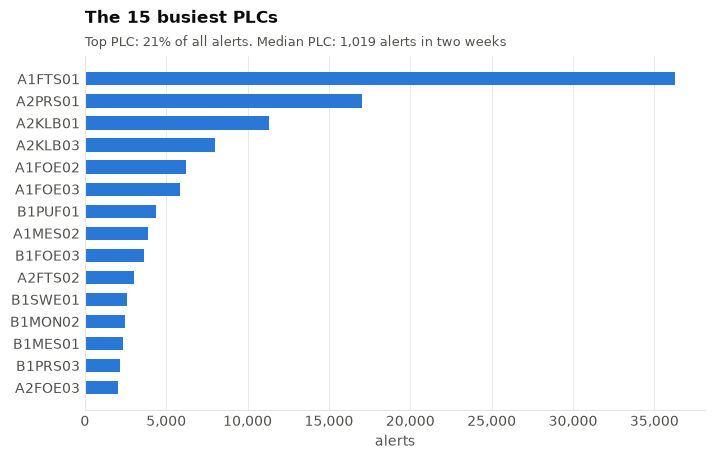

In [5]:
per_plc = alerts.alertPlc.value_counts()
top = per_plc.head(15)[::-1]

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top.index, top.values, color=SERIES[0], height=0.6)
ax.set_title("The 15 busiest PLCs")
plotting.subtitle(ax, f"Top PLC: {per_plc.iloc[0] / len(alerts):.0%} of all alerts. Median PLC: {int(per_plc.median()):,} alerts in two weeks")
ax.set_xlabel("alerts")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "data_alerts_per_plc.png")
plt.show()

## What a cascade looks like
One generated cascade, in firing order. The offsets are milliseconds after the first alert. This is the pattern Model 1 has to find among thousands of other rows.

In [6]:
sizes = truth[truth.cascade_id >= 0].groupby("cascade_id").agg(n=("alertId", "size"), plcs=("alertPlc", "nunique"))
example_id = sizes[(sizes.n == 8) & (sizes.plcs == 3)].index[0]
ids = truth.loc[truth.cascade_id == example_id, "alertId"]
example = alerts[alerts.alertId.isin(ids)].copy()
t = pd.to_datetime(example.alertBegin.str[:26])
example.insert(0, "ms after first", ((t - t.min()).dt.total_seconds() * 1000).round(1))
example[["ms after first", "alertPlc", "alertText", "alertIsBandStop", "alertCategory"]]

,ms after first,alertPlc,alertText,alertIsBandStop,alertCategory
34008,0.0,A2MON02,ZH3 Zweihandbedienung 4 gestoert,0,technical
34009,44.9,A2MON02,NP1 Nullpunktspanner 2 nicht gespannt,0,technical
34010,87.2,A2MES02,ID2 Bauteilkennung 20 nicht lesbar,0,technical
34011,211.7,A2MES02,ID2 Bauteilkennung 20 nicht lesbar,0,technical
34012,286.7,A2MES02,QS3 Pruefung 4 nicht in Ordnung,0,technical
34013,380.7,A2MES02,QS3 Pruefung 4 nicht in Ordnung,0,technical
34014,534.6,A2MON02,MW7 Messwert 15 unplausibel,0,technical
34015,687.8,A2PRF02,MW8 Messwert 17 unplausibel,1,technical


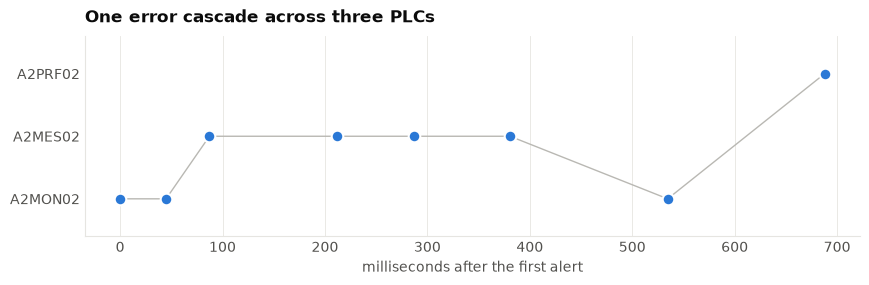

In [7]:
fig, ax = plt.subplots(figsize=(10, 2.6))
order = list(dict.fromkeys(example.alertPlc))
y = example.alertPlc.map({p: i for i, p in enumerate(order)})
ax.plot(example["ms after first"], y, color=MUTED, lw=1, zorder=1)
ax.scatter(example["ms after first"], y, s=70, color=SERIES[0], edgecolor="white", linewidth=1.5, zorder=2)
ax.set_yticks(range(len(order)), order)
ax.set_ylim(-0.6, len(order) - 0.4)
ax.set_xlabel("milliseconds after the first alert")
ax.set_title("One error cascade across three PLCs")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "data_example_cascade.png")
plt.show()

## Takeaway
- The structure to find sits in milliseconds. A cascade is over in about a second, and timestamps have to keep their full precision.
- Not everything that fires together is a cascade. Repeating devices produce tight bursts of one message, and busy stations produce coincidences.
- Volume is very uneven across PLCs, which is one reason the application processes one file per PLC.